In this notebook, we explain how to train a spatio-temporal model for hourly sea
surface temperature (SST) data using the ClimaNet libraries. This notebook
demonstrates the main steps, including data preparation, model configuration,
training, and evaluation and the relevant functions. So the results can be
different with different model configurations.

In [ ]:
from pathlib import Path
import xarray as xr
from climanet.st_encoder_decoder import SpatioTemporalModel
from climanet.utils import set_seed, configure_compute_resources, plot_results, plot_histograms, plot_loss, data_preparation, read_st_data, compute_anom_scale
from climanet.train import train_monthly_model, TrainConfig
from climanet.predict import predict_monthly_var, PredictionConfig
from climanet.dataset import STDataset, DataLoaderConfig

## Read data

In [ ]:
# Data is stored on Levante in the path below
data_folder = Path("/work/bd0854/b380103/eso4clima/output/sst/concatenated")
run_dir = Path("./runs_hourly")
var_name = "tos"

# 1 month train in 3 years, 1 month validation and 1 month test
hourly_data_train = xr.open_mfdataset([
    data_folder / f"201801_hr_ERA5dc_masked_{var_name}.nc",
    data_folder / f"201901_hr_ERA5dc_masked_{var_name}.nc",
    data_folder / f"202001_hr_ERA5dc_masked_{var_name}.nc",
])
hourly_data_validation = xr.open_mfdataset(data_folder / f"202101_hr_ERA5dc_masked_{var_name}.nc")
hourly_data_test = xr.open_mfdataset(data_folder / f"202201_hr_ERA5dc_masked_{var_name}.nc")

monthly_data_train = xr.open_mfdataset([
    data_folder / f"201801_mon_ERA5dc_full_{var_name}.nc",
    data_folder / f"201901_mon_ERA5dc_full_{var_name}.nc",
    data_folder / f"202001_mon_ERA5dc_full_{var_name}.nc",
])
monthly_data_validation = xr.open_mfdataset(data_folder / f"202101_mon_ERA5dc_full_{var_name}.nc")
monthly_data_test = xr.open_mfdataset(data_folder / f"202201_mon_ERA5dc_full_{var_name}.nc")

file_name = "/work/bd0854/eso4clima/era5_lsm_bool.nc"  # downloded from era5 and regridded using the function `regrid_to_boundary_centered_grid`
lsm_mask = xr.open_dataset(file_name)

## Subset data (for fast experimentation, randomly selected)

In [ ]:
# coordinates of subset
lon_subset = slice(-30, 30)
lat_subset = slice(-30, 30)

hourly_train_subset = hourly_data_train.sel(lon=lon_subset, lat=lat_subset)
monthly_train_subset = monthly_data_train.sel(lon=lon_subset, lat=lat_subset)
lsm_subset = lsm_mask.sel(lon=lon_subset, lat=lat_subset)  # True=Land

hourly_validation_subset = hourly_data_validation.sel(lon=lon_subset, lat=lat_subset)
monthly_validation_subset = monthly_data_validation.sel(lon=lon_subset, lat=lat_subset)

hourly_test_subset = hourly_data_test.sel(lon=lon_subset, lat=lat_subset)
monthly_test_subset = monthly_data_test.sel(lon=lon_subset, lat=lat_subset)

print(hourly_train_subset[var_name].shape, monthly_train_subset[var_name].shape)  # (time, lat, lon)

(2232, 240, 240) (3, 240, 240)


### Build the datasets

#### Prepare the train data

In [7]:
# this should be done once
data_dir = run_dir / "data_train"
input_da, input_da_nan_mask, monthly_da, padded_days_mask, time_features = data_preparation(
    hourly_train_subset[var_name], monthly_train_subset[var_name], calculate_residuals=True, is_hourly=True, save_to_zarr=True, run_dir=data_dir,
)

In [ ]:
# read data
data_dir = run_dir / "data_train"
input_da, input_da_nan_mask, monthly_da, padded_days_mask, time_features = read_st_data(data_path=data_dir, var_name=var_name)

In [9]:
# calculate stats of training data
anom_scale = compute_anom_scale(input_da, input_da_nan_mask, lsm_subset["lsm"])
print("Anomaly scale:", anom_scale)

Anomaly scale: 0.1518336832523346


In [ ]:
# calculate standard deviation of monthly data for training
STD_TRAIN = float(monthly_da.std(skipna=True).compute())
print(f"STD_TRAIN: {STD_TRAIN}")

STD_TRAIN: 0.0637732744216919


In [ ]:
# create dataset config
spatial_crop_size = (1, 40, 40)
model_patch_size = (1, 4, 4)

# normalize monthly data for training
monthly_da_norm = monthly_da / STD_TRAIN

dataset_train = STDataset(
    input_da=input_da,
    input_da_nan_mask=input_da_nan_mask,
    monthly_da=monthly_da_norm,
    padded_days_mask=padded_days_mask,
    time_features=time_features,
    land_mask=lsm_subset["lsm"],
    model_patch_size=model_patch_size,
    crop_size=spatial_crop_size,   # based on the patch_size in model
    stride=None,
    verbose=True,
    load_lazy=False,
    augment=True,  # for data augmentation during training
    p_aug=0.5,
    drop_range=(0.1, 0.5),
    min_obs=5,
    target_scale=STD_TRAIN,
)

Creating dataset:
Crop grid (m x i x j): 3 x 6 x 6 = 108 data crops
Overlap: 0 pixels (height), 0 pixels (width)


#### Prepare validation data

In [13]:
# this should be done once
data_dir = run_dir / "data_validation"
input_da, input_da_nan_mask, monthly_da, padded_days_mask, time_features = data_preparation(
    hourly_validation_subset[var_name], monthly_validation_subset[var_name], calculate_residuals=True, is_hourly=True, save_to_zarr=True, run_dir=data_dir,
)

In [ ]:
# read data
data_dir = f"{run_dir}/data_validation"
input_da, input_da_nan_mask, monthly_da, padded_days_mask, time_features = read_st_data(data_path=data_dir, var_name=var_name)

In [13]:
# create dataset config
spatial_crop_size = (1, 40, 40)
model_patch_size = (1, 4, 4)

# normalize monthly data for training
monthly_da_norm = monthly_da / STD_TRAIN

dataset_validation = STDataset(
    input_da=input_da,
    input_da_nan_mask=input_da_nan_mask,
    monthly_da=monthly_da_norm,
    padded_days_mask=padded_days_mask,
    time_features=time_features,
    land_mask=lsm_subset["lsm"],
    model_patch_size=model_patch_size,
    crop_size=spatial_crop_size,   # based on the patch_size in model
    verbose=True,
    load_lazy=False,
)
print(len(dataset_validation))

Creating dataset:
Crop grid (m x i x j): 1 x 6 x 6 = 36 data crops
Overlap: 0 pixels (height), 0 pixels (width)
36


In [ ]:
# create the model (small)
set_seed()

# Device and resources
dataloader_num_workers = 2
device = "cuda"

In [15]:
# create dataloader config
dataloader_config = DataLoaderConfig(
    batch_size=36,
    shuffle=True,
    num_workers=dataloader_num_workers,
    pin_memory=True,
    persistent_workers=True,
    device=device,
    multiprocessing_context=None, # set this to "spawn" when num_workers >0 and lazy data
)
dataloader_config

DataLoaderConfig(batch_size=36, shuffle=True, num_workers=2, pin_memory=True, persistent_workers=True, device='cuda', multiprocessing_context=None)

## Build the model and train config

In [ ]:
model = SpatioTemporalModel(patch_size=model_patch_size, embed_dim=32, dropout=0.05, hidden=32, encoder_proj_dim=16, anom_scale=anom_scale, target_scale=STD_TRAIN)

model = configure_compute_resources(model, device=device, compute_threads=None, dataloader_num_workers=dataloader_num_workers)

In [17]:
# create training config
training_config = TrainConfig(
    calculate_residuals=True,
    num_epoch=101,
    patience=20,
    accumulation_steps=1,
    optimizer_lr=1e-3,
    optimizer_weight_decay=0.0001,
    scheduler_min_lr=1e-6,
    device=device,
    verbose=True,
    verbose_epoch_interval=10,
    tune_checkpoint=False,
    store_model=True,
    store_logs=True,
)
training_config

TrainConfig(calculate_residuals=True, num_epoch=101, patience=20, accumulation_steps=1, optimizer_lr=0.001, optimizer_weight_decay=0.0001, scheduler_lr_factor=0.1, scheduler_min_lr=1e-06, device='cuda', verbose=True, verbose_epoch_interval=10, tune_checkpoint=False, store_model=True, store_logs=True)

### Start training loop

In [18]:
%%time
# verbose is True
trained_model = train_monthly_model(
    model=model,
    dataset_train=dataset_train,
    dataloader_config=dataloader_config,
    training_config=training_config,
    dataset_validation=dataset_validation,
    run_dir=run_dir,
)

Epoch 0: gap between train and val loss: -0.373438
Epoch 0: train loss = 1.218363, val loss = 0.844924
Epoch 0: best_loss = 0.844924
Epoch 0: time elapsed = 9.88s
Epoch 10: gap between train and val loss: -0.398223
Epoch 10: train loss = 0.947212, val loss = 0.548989
Epoch 10: best_loss = 0.548989
Epoch 10: time elapsed = 4.31s
Epoch 20: gap between train and val loss: -0.205201
Epoch 20: train loss = 0.666842, val loss = 0.461641
Epoch 20: best_loss = 0.460131
Epoch 20: time elapsed = 4.34s
Epoch 30: gap between train and val loss: -0.214743
Epoch 30: train loss = 0.627612, val loss = 0.412869
Epoch 30: best_loss = 0.412869
Epoch 30: time elapsed = 4.18s
Epoch 40: gap between train and val loss: -0.093299
Epoch 40: train loss = 0.533666, val loss = 0.440367
Epoch 40: best_loss = 0.412869
Epoch 40: time elapsed = 4.53s
Epoch 50: gap between train and val loss: -0.225293
Epoch 50: train loss = 0.627891, val loss = 0.402597
Epoch 50: best_loss = 0.399534
Epoch 50: time elapsed = 4.31s
Ep

## Inspect results and compare

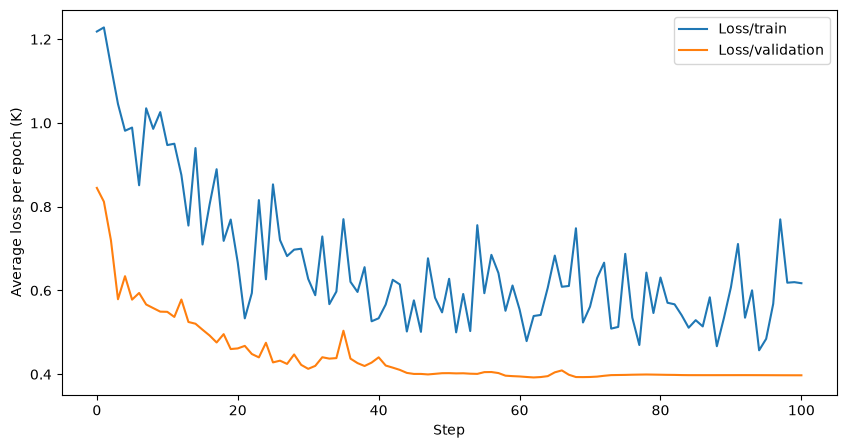

In [19]:
plot_loss(run_dir, list_loss_var=["Loss/train", "Loss/validation"], unit="K")

The validation loss is lower than training loss because:
- we use data augmentation during training, which can increase the training loss compared to the validation loss
- we use dropout which is active during training but not during validation, leading to higher training loss.

#### Prepare the test data

In [21]:
# this hsould be done once
data_dir = f"{run_dir}/data_test"
input_da, input_da_nan_mask, monthly_da, padded_days_mask, time_features = data_preparation(
    hourly_test_subset[var_name], monthly_test_subset[var_name], calculate_residuals=True, is_hourly=True, save_to_zarr=True, run_dir=data_dir,
)

In [ ]:
# read data
data_dir = f"{run_dir}/data_test"
input_da, input_da_nan_mask, monthly_da, padded_days_mask, time_features = read_st_data(data_path=data_dir, var_name=var_name)

In [ ]:
# normalize monthly data for training
monthly_da_norm = monthly_da / STD_TRAIN

dataset_test = STDataset(
    input_da=input_da,
    input_da_nan_mask=input_da_nan_mask,
    monthly_da=monthly_da_norm,
    padded_days_mask=padded_days_mask,
    time_features=time_features,
    land_mask=lsm_subset["lsm"],
    model_patch_size=model_patch_size,
    crop_size=(1, *monthly_da.shape[1:]),  # the whole dataset
    verbose=True,
    load_lazy=False,
)
print(len(dataset_test))

Creating dataset:
Crop grid (m x i x j): 1 x 1 x 1 = 1 data crops
Overlap: 0 pixels (height), 0 pixels (width)
1


In [22]:
# create dataloader config
dataloader_config = DataLoaderConfig(
    batch_size=36,
    shuffle=False,   # no shuffling in inference
    num_workers=0,
    pin_memory=True,
    persistent_workers=False,
    device=device,
    multiprocessing_context=None, # keep this when num_workers >0 and lazy data
)
dataloader_config

DataLoaderConfig(batch_size=36, shuffle=False, num_workers=0, pin_memory=True, persistent_workers=False, device='cuda', multiprocessing_context=None)

In [23]:
# create prediction config
prediction_config = PredictionConfig(
    calculate_residuals=True,
    return_numpy=True,
    save_predictions=True,
    return_loss=False,
    device=device,
    verbose=False,
)

In [ ]:
# inference on test data, verbose is True
predictions = predict_monthly_var(
    model=f"{run_dir}/best_model.pth",
    dataset=dataset_test,
    dataloader_config=dataloader_config,
    prediction_config=prediction_config,
    run_dir=run_dir,
)

In [25]:
# add to monthly average
predictions_res = xr.open_dataset(f"{run_dir}/202201_{var_name}_prediction_residual.nc")

In [26]:
# add to monthly average
input_data_averaged = hourly_test_subset.resample({"time": "MS"}).mean(skipna=True)
input_data_averaged["time"] = monthly_test_subset["time"]
baseline_res = monthly_test_subset - input_data_averaged

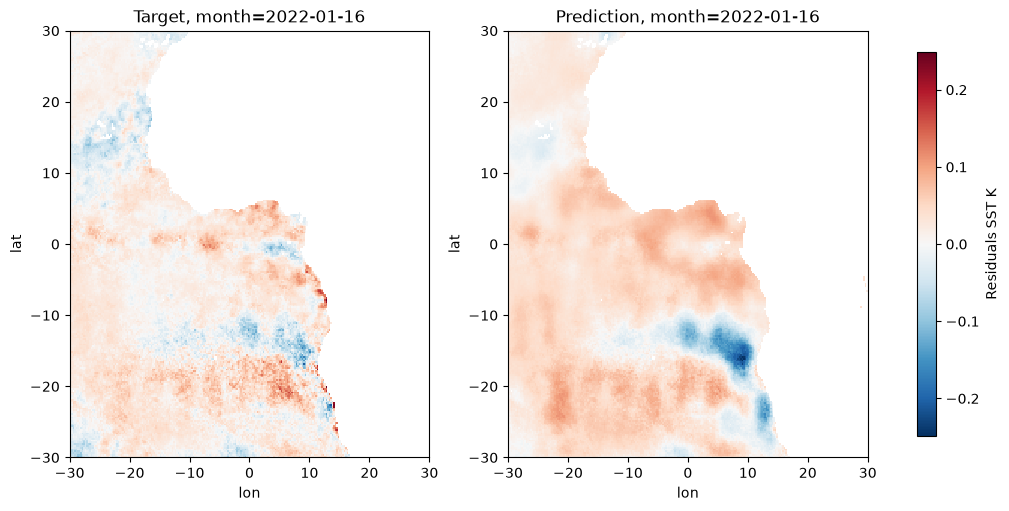

In [27]:
ocean = ~lsm_subset["lsm"].values
masked_target = baseline_res[var_name].where(ocean)
masked_pred = predictions_res[var_name].where(ocean)
plot_results(masked_target, masked_pred, label="Residuals SST K", title=("Target", "Prediction"))

The spatial structure can be improved by hyperparameter tuning, such as adjusting the patch size, embedding dimension, and hidden layer size in the model.
Additionally, experimenting with different types of data augmentation and regularization techniques can help the model better capture spatial dependencies.

In [ ]:
err_baseline = (monthly_test_subset[var_name] - input_data_averaged[var_name])   # M - mean(D)
err_predictions = (baseline_res[var_name] - predictions_res[var_name])  # M - M_hat

ocean = ~lsm_subset["lsm"].values
masked_err_baseline = err_baseline.where(ocean)
masked_err_predictions = err_predictions.where(ocean)

plot_results(masked_err_baseline, masked_err_predictions, label="error K", title=("err_Baseline", "err_Prediction"), error=True)

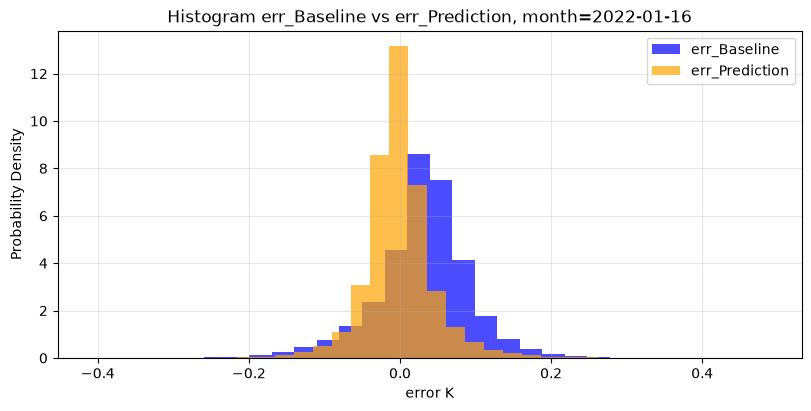

In [29]:
plot_histograms(masked_err_baseline, masked_err_predictions, label="error K", legend_labels=("err_Baseline", "err_Prediction"))